In [2]:
import os

# Tell joblib how many CPU cores to use
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

sns.set_style("whitegrid")

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
df = pd.read_csv("../data/processed_traffic.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (48120, 7)


,DateTime,Junction,Vehicles,ID,hour,day_of_week,day_name
0,2015-11-01 00:00:00,1,15,20151101001,0,6,Sunday
1,2015-11-01 01:00:00,1,13,20151101011,1,6,Sunday
2,2015-11-01 02:00:00,1,10,20151101021,2,6,Sunday
3,2015-11-01 03:00:00,1,7,20151101031,3,6,Sunday
4,2015-11-01 04:00:00,1,9,20151101041,4,6,Sunday


In [4]:
X = df[[
    "hour",
    "Vehicles"
]].copy()

print(X.head())

   hour  Vehicles
0     0        15
1     1        13
2     2        10
3     3         7
4     4         9


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (48120, 2)


In [7]:
inertia = []
silhouette_scores = []

K_range = range(2, 7)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

print("Results:")

for k, inertia_value, score in zip(
    K_range,
    inertia,
    silhouette_scores
):
    print(
        f"K = {k} | "
        f"Inertia = {inertia_value:.2f} | "
        f"Silhouette = {score:.4f}"
    )

Results:
K = 2 | Inertia = 55135.66 | Silhouette = 0.4249
K = 3 | Inertia = 29421.85 | Silhouette = 0.4852
K = 4 | Inertia = 22935.02 | Silhouette = 0.4769
K = 5 | Inertia = 18033.30 | Silhouette = 0.4136
K = 6 | Inertia = 14408.55 | Silhouette = 0.4243


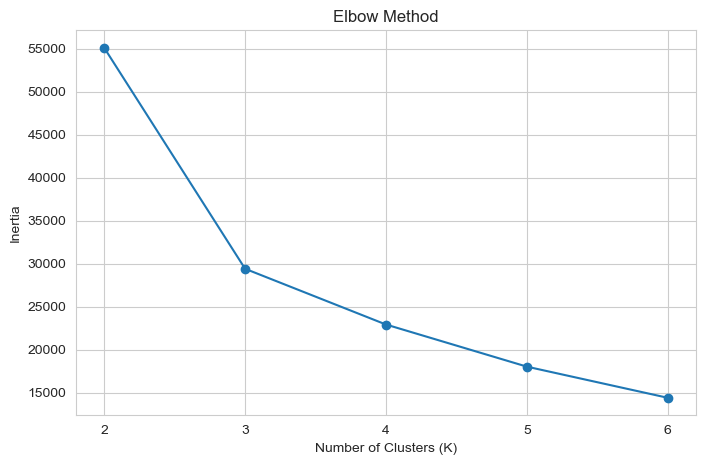

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(K_range),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.xticks(list(K_range))
plt.show()

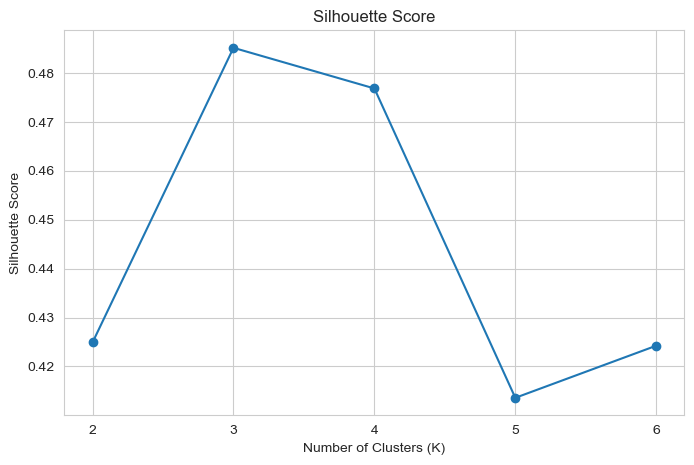

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(K_range),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")

plt.xticks(list(K_range))
plt.show()

In [10]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X_scaled)

print(df["cluster"].value_counts())

cluster
1    22183
2    19445
0     6492
Name: count, dtype: int64


In [11]:
cluster_summary = df.groupby("cluster").agg({
    "Vehicles": ["mean", "min", "max"],
    "hour": "mean"
})

display(cluster_summary)

Vehicles                hour
              mean min  max       mean
cluster                               
0        66.119378  40  180  14.894331
1        14.540504   1   57   5.284272
2        17.738236   1   45  17.457701

In [12]:
cluster_means = df.groupby("cluster")["Vehicles"].mean()

sorted_clusters = cluster_means.sort_values().index.tolist()

cluster_names = {
    sorted_clusters[0]: "Low Traffic",
    sorted_clusters[1]: "Moderate Traffic",
    sorted_clusters[2]: "High Traffic"
}

df["traffic_level"] = df["cluster"].map(cluster_names)

print(df["traffic_level"].value_counts())

traffic_level
Low Traffic         22183
Moderate Traffic    19445
High Traffic         6492
Name: count, dtype: int64


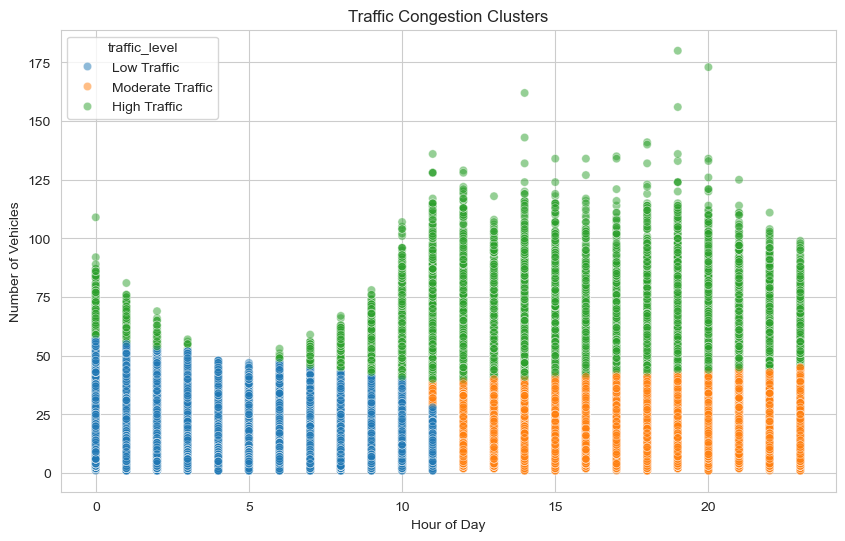

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="hour",
    y="Vehicles",
    hue="traffic_level",
    alpha=0.5
)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Vehicles")
plt.title("Traffic Congestion Clusters")

plt.show()

In [14]:
final_score = silhouette_score(
    X_scaled,
    df["cluster"],
    sample_size=5000,
    random_state=42
)

print(f"Final Silhouette Score: {final_score:.4f}")

Final Silhouette Score: 0.4846


In [15]:
df.to_csv(
    "../data/traffic_with_clusters.csv",
    index=False
)

print("Clustering completed successfully!")

Clustering completed successfully!
